In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


PROJECT_ROOT = '/content/data/spatial/grid_rectangles.geojson'
DATA_DIR = '/content/data'

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict



In [ ]:
from pathlib import Path

# ── Load all layers ───────────────────────────────────────────────────────
LAYER_DIR = Path(DATA_DIR) / 'kriging_satellite' / 'layers'
SV_DIR    = Path(DATA_DIR) / 'kriging_street_view'

sat_layer_paths = {
    'ndvi':         LAYER_DIR / 'ndvi_grid.geojson',
    'ndbi':         LAYER_DIR / 'ndbi_grid.geojson',
    'impervious':   LAYER_DIR / 'nlcd_impervious_grid.geojson',
    'road_density': LAYER_DIR / 'road_density_grid.geojson',
}
sv_layer_paths = {
    'gvi':        SV_DIR / 'grid_aggregated_gvi.geojson',
    'facades':    SV_DIR / 'grid_aggregated_facade_area.geojson',
    'cars':       SV_DIR / 'grid_aggregated_n_cars.geojson',
    'sky_ratio':  SV_DIR / 'grid_aggregated_sky_ratio.geojson',
    'road_ratio': SV_DIR / 'grid_aggregated_road_ratio.geojson',
}

missing = [k for k, p in {**sat_layer_paths, **sv_layer_paths}.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f'Missing layers: {missing}')

sat_gdfs = {name: gpd.read_file(path) for name, path in sat_layer_paths.items()}
sv_gdfs  = {name: gpd.read_file(path) for name, path in sv_layer_paths.items()}
print('SAT layers:', list(sat_gdfs))
print('SV  layers:', list(sv_gdfs))

SAT layers: ['ndvi', 'ndbi', 'impervious', 'road_density']
SV  layers: ['gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']


In [ ]:
SENSORS_DIR = Path(DATA_DIR) / 'sensors'
sensor_csvs = {
    'Boston Carter Field':               SENSORS_DIR / 'boston_carter_field'         / 'boston_carter_field.csv',
    'Boston Gainsborough Parking Garage': SENSORS_DIR / 'boston_gainsborough_parking' / 'boston_gainsborough_parking.csv',
    'Boston Robinson Hall':              SENSORS_DIR / 'boston_robinson_hall'         / 'boston_robinson_hall.csv',
    'Boston West Village B':             SENSORS_DIR / 'boston_west_village_b'        / 'boston_west_village_b.csv',
    'Boston World Series Way':           SENSORS_DIR / 'boston_world_series_way'      / 'boston_world_series_way.csv',
}

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}
aligned_df, _ = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name='pm25',
    time_column='timestamp',
    sampling_interval='1min',
    timestamp_tolerance='15min',
)
sensor_pm25 = aligned_df.between_time('15:00', '16:00').mean(axis=0)

sensor_locations_raw = pd.read_csv(Path(DATA_DIR) / 'spatial' / 'data-1775857265051.csv')
sensor_names = list(sensor_csvs.keys())

sensor_name_map = {
    'Robinson Hall': 'Boston Robinson Hall',
    'West Village B': 'Boston West Village B',
    'Gainsborough Parking Garage': 'Boston Gainsborough Parking Garage',
    'Carter Field': 'Boston Carter Field',
    'World Series Way': 'Boston World Series Way',
    'World Series Way-2': 'Boston World Series Way',
}

sensor_locations_raw['ecohub_location'] = sensor_locations_raw['ecohub_location'].apply(lambda x: sensor_name_map.get(x, x))

sensor_pm25_df = sensor_pm25.rename('pm25').reset_index().rename(columns={'index': 'ecohub_location'})

final_sensor_df = pd.merge(
    sensor_locations_raw,
    sensor_pm25_df,
    on='ecohub_location',
    how='inner'
)

final_sensor_df = final_sensor_df[final_sensor_df['ecohub_location'].isin(sensor_names)]

final_sensor_df = final_sensor_df.rename(columns={'ecohub_location': 'sensor_name'})

if final_sensor_df.empty:
    raise ValueError(
        "No matching sensor locations found for the provided sensor names. "
        "Please check sensor names in the CSV and `sensor_csvs` dictionary."
    )

gdf_sensors = gpd.GeoDataFrame(
    final_sensor_df,
    geometry=gpd.points_from_xy(final_sensor_df['lon'], final_sensor_df['lat']),
    crs='EPSG:4326',
)
print(f'Sensors loaded: {len(gdf_sensors)}')
gdf_sensors[['sensor_name', 'pm25', 'geometry']]

Sensors loaded: 4


,sensor_name,pm25,geometry
0,Boston Robinson Hall,0.003135,POINT (-71.08652 42.33919)
1,Boston West Village B,0.884483,POINT (-71.09238 42.33765)
2,Boston Gainsborough Parking Garage,16.439812,POINT (-71.08508 42.34039)
3,Boston Carter Field,10.322884,POINT (-71.08435 42.33925)


In [ ]:
def _ensure_grid_id(gdf):
    if 'grid_id' in gdf.columns: return gdf.copy()
    if 'id'      in gdf.columns: return gdf.copy().rename(columns={'id': 'grid_id'})
    return gdf.reset_index(drop=False).rename(columns={'index': 'grid_id'})

def _pick_col(gdf, candidates):
    for c in candidates:
        if c in gdf.columns: return c
    raise ValueError(f'None of {candidates} in {list(gdf.columns)}')

sat_specs = [
    ('ndvi',         ['ndvi', 'ndvi_mean']),
    ('ndbi',         ['ndbi', 'ndbi_mean']),
    ('impervious',   ['impervious', 'nlcd_impervious']),
    ('road_density', ['road_density_km_km2', 'road_density']),
]
sv_specs = [
    ('gvi',        ['gvi_mean', 'gvi']),
    ('facades',    ['facade_area_mean', 'facade_area', 'facades']),
    ('cars',       ['n_cars_mean', 'n_cars', 'cars']),
    ('sky_ratio',  ['sky_ratio_mean', 'sky_ratio']),
    ('road_ratio', ['road_ratio_mean', 'road_ratio']),
]

base = _ensure_grid_id(sat_gdfs['ndvi'])
base_crs = base.crs
grid_features = base[['grid_id', 'geometry']].copy()

for out_name, candidates in sat_specs:
    layer = _ensure_grid_id(sat_gdfs[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

for out_name, candidates in sv_specs:
    layer = _ensure_grid_id(sv_gdfs[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

# road_density NaNs = 0 (no road), SV NaNs = median
grid_features['road_density'] = grid_features['road_density'].fillna(0.0)
print(f'Grid cells: {len(grid_features)}')
print(f'NaN counts:\n{grid_features.drop(columns=["grid_id","geometry"]).isna().sum()}')

Grid cells: 900
NaN counts:
ndvi             0
ndbi             0
impervious       0
road_density     0
gvi             43
facades         43
cars            43
sky_ratio       43
road_ratio      43
dtype: int64


In [ ]:
target_col   = 'pm25'
K_RANGE      = range(2, 11)
K_FINAL      = None
RANDOM_STATE = 42

predictor_cols_kmeans = [
    'ndvi', 'ndbi', 'road_density_log1p', 'gvi', 'cars_log1p',
]

In [ ]:
for col in predictor_cols_kmeans:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

# ── Scale ──────────────────────────────────────────────────────────────────
scaler        = StandardScaler()
X_grid_scaled = scaler.fit_transform(grid_features[predictor_cols_kmeans])

In [ ]:
from sklearn.metrics import silhouette_score
inertias   = []
sil_scores = []

for k in K_RANGE:
    km     = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_grid_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_grid_scaled, labels))

if K_FINAL is None:
    K_FINAL = list(K_RANGE)[int(np.argmax(sil_scores))]
    print(f'\nAuto-selected K = {K_FINAL}  (highest silhouette = {max(sil_scores):.4f})')
else:
    print(f'\nUsing forced K = {K_FINAL}')


Auto-selected K = 2  (highest silhouette = 0.3073)


In [ ]:
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
grid_features['cluster'] = kmeans_final.fit_predict(X_grid_scaled)

print(f'\nCluster distribution (grid cells):\n'
      f'{grid_features["cluster"].value_counts().sort_index().to_string()}')


Cluster distribution (grid cells):
cluster
0    583
1    317


In [ ]:
sensors_proj     = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(sensors_proj, grid_features, how='left', predicate='within')

unmatched = sensor_with_grid['grid_id'].isna()
if unmatched.any():
    nearest = gpd.sjoin_nearest(
        sensors_proj.loc[unmatched].copy(),
        grid_features,
        how='left',
        distance_col='_d',
    )
    sensor_with_grid.loc[unmatched, ['grid_id', 'cluster'] + predictor_cols_kmeans] = \
        nearest[['grid_id', 'cluster'] + predictor_cols_kmeans].to_numpy()

sensor_cell_df = pd.DataFrame({
    'sensor_name': sensor_with_grid['sensor_name'],
    target_col:    sensor_with_grid[target_col],
    'grid_id':     sensor_with_grid['grid_id'],
    'cluster':     sensor_with_grid['cluster'].astype(int),
    **{c: sensor_with_grid[c] for c in predictor_cols_kmeans},
}).drop_duplicates(subset=['sensor_name']).reset_index(drop=True)

In [ ]:
cluster_temp_map = (
    sensor_cell_df
    .groupby('cluster')[target_col]
    .mean()
    .rename(f'mean_{target_col}')
)

print(f'\nMean {target_col} per cluster:')
print(cluster_temp_map.to_string())


Mean pm25 per cluster:
cluster
0    13.381348
1     0.443809


In [ ]:
grid_features[f'predicted_{target_col}'] = grid_features['cluster'].map(cluster_temp_map)
raw_cols = ['ndvi', 'ndbi', 'road_density', 'gvi', 'cars']
cluster_stats = (
    grid_features
    .groupby('cluster')[raw_cols]
    .agg(['mean', 'std'])
    .round(4)
)
cluster_stats.columns = ['_'.join(c) for c in cluster_stats.columns]
cluster_stats[f'mean_{target_col}'] = cluster_temp_map
cluster_stats['n_grid_cells']     = grid_features['cluster'].value_counts().sort_index()

print('\nPer-cluster feature statistics:')
print(cluster_stats.to_string())


Per-cluster feature statistics:
         ndvi_mean  ndvi_std  ndbi_mean  ndbi_std  road_density_mean  road_density_std  gvi_mean  gvi_std  cars_mean  cars_std  mean_pm25  n_grid_cells
cluster                                                                                                                                                
0           0.1207    0.0504    -0.0674    0.0393            28.9048           24.9658    0.1301   0.0568     8.2857    4.1554  13.381348           583
1           0.2803    0.0784    -0.1795    0.0551            16.5734           18.2993    0.1937   0.0726     6.3127    4.0125   0.443809           317


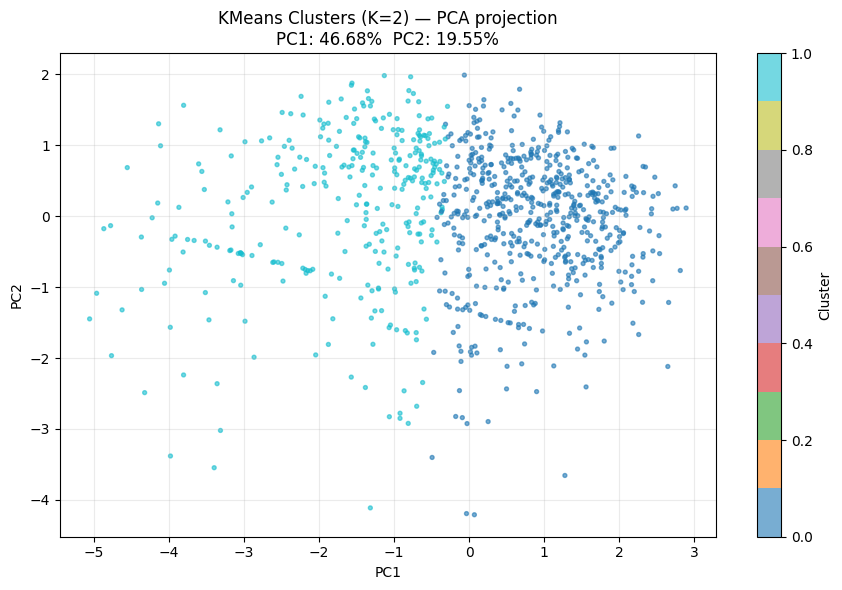

Cluster PCA plot saved.


In [ ]:
pca_vis = PCA(n_components=2, random_state=RANDOM_STATE)
X_vis   = pca_vis.fit_transform(X_grid_scaled)

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(
    X_vis[:, 0], X_vis[:, 1],
    c=grid_features['cluster'],
    cmap='tab10', s=8, alpha=0.6,
)
plt.colorbar(sc, ax=ax, label='Cluster')
ax.set_title(
    f'KMeans Clusters (K={K_FINAL}) — PCA projection\n'
    f'PC1: {pca_vis.explained_variance_ratio_[0]:.2%}  '
    f'PC2: {pca_vis.explained_variance_ratio_[1]:.2%}',
    fontsize=12,
)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig('kmeans_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print('Cluster PCA plot saved.')

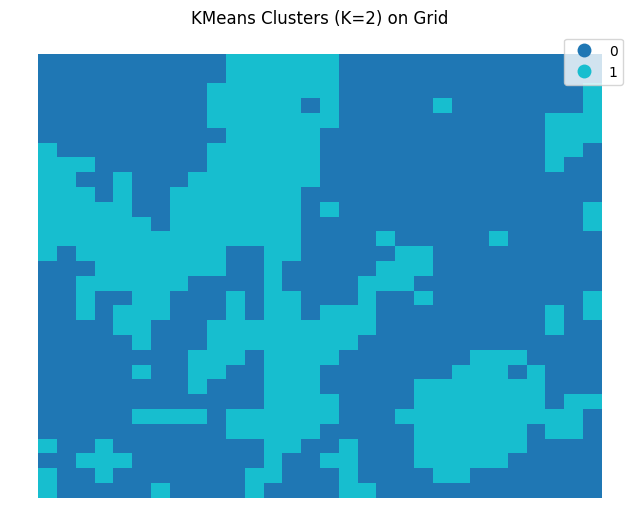

In [ ]:
cluster_map = gpd.GeoDataFrame(grid_features, geometry='geometry', crs=base_crs)

fig, ax = plt.subplots(figsize=(8, 8))
cluster_map.plot(column='cluster', cmap='tab10', legend=True, ax=ax, categorical=True)
ax.set_axis_off()
ax.set_title(f'KMeans Clusters (K={K_FINAL}) on Grid')
plt.show()

In [ ]:
pca_vis = PCA(n_components=2, random_state=RANDOM_STATE)
X_vis   = pca_vis.fit_transform(X_grid_scaled)

# If K_FINAL somehow got reset to None, re-evaluate it based on sil_scores
# This assumes K_RANGE and sil_scores are still available from previous execution
if K_FINAL is None:
    K_FINAL = list(K_RANGE)[int(np.argmax(sil_scores))]

# ── Summary ───────────────────────────────────────────────────────────────
print('\n── KMeans Summary ──────────────────────────────────────────────────')
print(f'  Features         : {predictor_cols_kmeans}')
print(f'  K selected       : {K_FINAL}')
print(f'  Silhouette score : {sil_scores[K_FINAL - min(K_RANGE)]:.4f}')
print(f'  Grid cells total : {len(grid_features)}')
print(f'  Sensors mapped   : {len(sensor_cell_df)}')
print((f'  Predicted {target_col} range : \n'
       f'      {grid_features[f"predicted_{target_col}"].min():.2f} – '
       f'{grid_features[f"predicted_{target_col}"].max():.2f}'))


── KMeans Summary ──────────────────────────────────────────────────
  Features         : ['ndvi', 'ndbi', 'road_density_log1p', 'gvi', 'cars_log1p']
  K selected       : 2
  Silhouette score : 0.3073
  Grid cells total : 900
  Sensors mapped   : 4
  Predicted pm25 range : 
      0.44 – 13.38
